# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [2]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

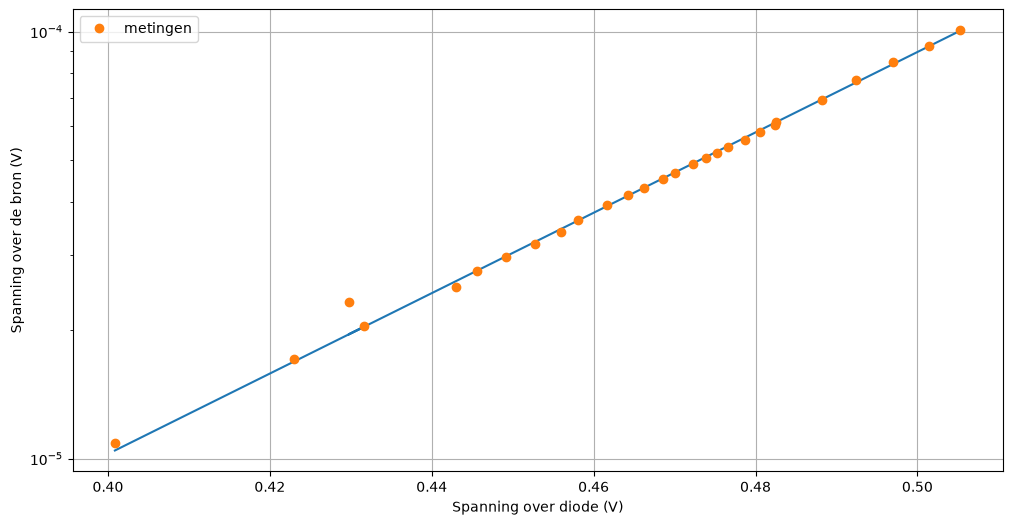

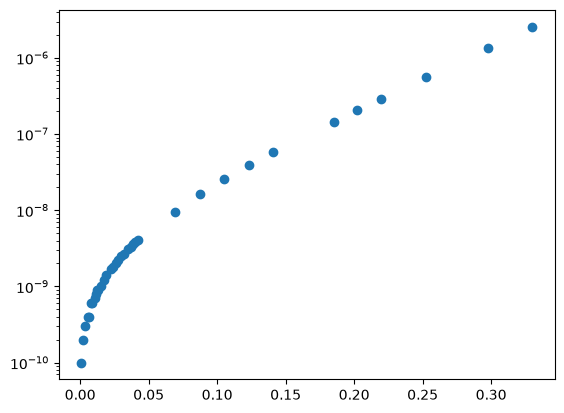

b = 21.6699 ± 0.1736 1/V
k_B = (1.261e-23 ± 6.4e-25) J/K
Referentiewaarde = 1.380649e-23 J/K
Relatieve afwijking = 8.66%


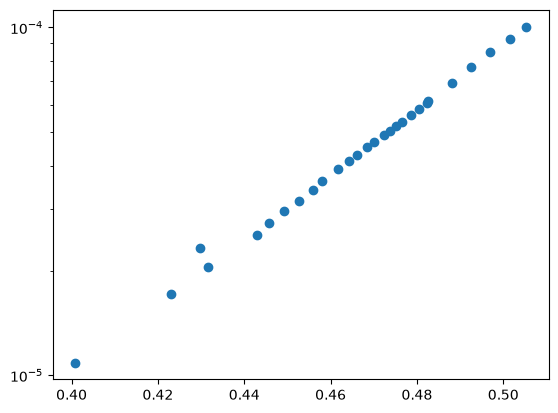

<Figure size 640x480 with 0 Axes>

In [3]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!

R1 = 9.9948e3  # weerstand in ohm
R2 = 10.0154e3 # ohm
R3 = 0.99457e3 # ohm

U_bron_oud = np.array([0.00870, 0.0188, 0.0389, 0.0592, 0.068, 0.088, 0.098, 0.119, 0.129, 0.139, 0.148, 0.169,\
                  0.189, 0.209, 0.248, 0.268, 0.289, 0.308, 0.328, 0.358, 0.387, 0.407, 0.428,0.447, 0.468, 0.767, 0.967,\
                  1.167, 1.366, 1.566, 2.065, 2.265, 2.465, 2.865, 3.464, 3.963, ])  # bronspanningen in V
U_R_oud = np.array([0.001, 0.002, 0.003, 0.004, 0.004, 0.006, 0.006, 0.007, 0.008, 0.009, 0.009, 0.010, \
               0.012, 0.014, 0.017, 0.018, 0.020, 0.022, 0.025, 0.027, 0.031, 0.033, 0.036,0.038, 0.041, 0.095, 0.163,\
               0.255, 0.387, 0.574, 1.441, 2.048, 2.885, 5.563, 13.640, 25.716, ])  # spanning over R1 in mV

U_R_klopt = U_R_oud* 1e-3

U_bron = np.array([5.75, 6.75, 7.25, 7.56, 7.95, 8.25, 8.55, 8.85, 9.15, 9.44, 9.84, 10.14, 10.34,\
                   10.64, 10.84, 11.14, 11.34, 11.54, 11.74, 12.04, 12.34, 12.64,\
                  12.74, 13.74, 14.73, 15.73, 16.73, 17.73]) # bronspanning in V
U_R = np.array([0.10872, 0.1713, 0.2048, 0.23218, 0.252341, 0.27473, 0.2963, 0.31789, 0.33984, 0.36190, 0.39178, 0.41421, 0.42900,\
                0.45172, 0.46685, 0.48966, 0.50482, 0.52013, 0.53545, 0.55839, 0.58155, 0.60468,\
                0.61282, 0.69048, 0.76861, 0.84723, 0.92601, 1.00531]) # spanning over R1 in V


# Verwerking van de meetgegevens

I_D_klopt = U_R_klopt / R1

U_klopt = (U_bron_oud / R2 - I_D_klopt) / (1/R2 + 1/R3)

U_D_klopt = U_klopt - U_R_klopt
# Verwerking met correctie voor belasting spanningsdeler

I_D = U_R / R1

U = (U_bron / R2 - I_D) / (1/R2 + 1/R3)

U_D = U - U_R


# Exponentieel model
def diode_model(U_D, I0, b):
    return I0 * np.expm1(b * U_D)

# Fit nadat voldoende metingen zijn ingevoerd
popt, pcov = curve_fit(diode_model, U_D, I_D, p0 =[1e-9, 20], maxfev=20000)

# Grafiek van de diodekarakteristiek
plt.figure(figsize = (12,6))
plt.plot(U_D, diode_model(U_D, *popt))
plt.xlabel("Spanning over diode (V)")
plt.ylabel("Spanning over de bron (V)")
plt.grid()
plt.semilogy(U_D, I_D,'o', label = "metingen")
plt.legend()
plt.show()

plt.figure()
plt.scatter(U_D_klopt, I_D_klopt)
plt.yscale('log')
plt.show()



plt.figure()
plt.scatter(U_D, I_D)
plt.yscale('log')
plt.figure()

# Constante van Boltzmann berekenen

q = -1.602176634e-19  # elektronlading (C)
n = 2.0                # idealiteitsfactor
u_n = 0.1              # onzekerheid in n

T = 293.15             # temperatuur (K), voorbeeld: 20 °C
u_T = 1.0              # voorbeeldonzekerheid (K)

# Fitparameter b en bijbehorende onzekerheid
b = popt[1]
u_b = np.sqrt(pcov[1, 1])

# Boltzmannconstante
k_B = -q / (b * n * T)

# Onzekerheidsvoortplanting
u_k_B = abs(k_B) * np.sqrt(
    (u_b / b)**2 +
    (u_n / n)**2 +
    (u_T / T)**2)

# Referentiewaarde
k_B_ref = 1.380649e-23

print(f"b = {b:.4f} ± {u_b:.4f} 1/V")
print(f"k_B = ({k_B:.3e} ± {u_k_B:.1e}) J/K")
print(f"Referentiewaarde = {k_B_ref:.6e} J/K")
print(f"Relatieve afwijking = {abs(k_B-k_B_ref)/k_B_ref*100:.2f}%")



**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [15]:
# Meetonzekerheid bronspanning (Dynatek)
digit_bron = np.select(
    [U_bron_all < 0.2, U_bron_all < 2],
    [0.0001, 0.001],
    default=0.01
)

u_U_bron = (0.005 * U_bron_all + digit_bron) / np.sqrt(3)

# Meetonzekerheid spanning over R1 (Thurlby)
bereik = np.where(U_R_all <= 0.210, 0.210, 2.1)
digit = np.where(U_R_all <= 0.210, 1e-6, 1e-5)
percentage = np.where(U_R_all <= 0.210, 0.00015, 0.0002)

u_U_R = (percentage * U_R_all + 0.00002 * bereik + digit) / np.sqrt(3)

# Uitgaande van weerstandsmetingen met de Thurlby
u_R1 = (0.0004 * R1 + 0.00002 * 21000 + 2 * 0.1) / np.sqrt(3)
u_R2 = (0.0004 * R2 + 0.00002 * 21000 + 2 * 0.1) / np.sqrt(3)
u_R3 = (0.0005 * R3 + 0.00002 * 2100 + 2 * 0.01) / np.sqrt(3)

u_I_D = np.sqrt(
    (u_U_R / R1)**2 +
    (U_R_all * u_R1 / R1**2)**2)

A = 1/R2 + 1/R3

u_U_D = np.sqrt(
    (u_U_bron / (R2 * A))**2 +
    ((1 + 1/(R1*A)) * u_U_R)**2 +
    (U_R_all * u_R1 / (R1**2*A))**2 +
    ((U_all - U_bron_all) * u_R2 / (R2**2*A))**2 +
    (U_all * u_R3 / (R3**2*A))**2
)

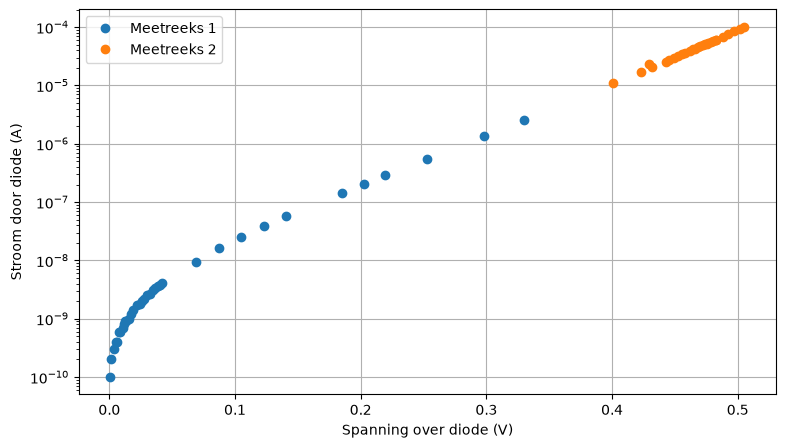

In [8]:
#Data processing and analysis:
U_bron_all = np.concatenate([U_bron_oud, U_bron])
U_R_all = np.concatenate([U_R_oud * 1e-3, U_R]) # alle berekeningen opnieuw met alle metingen 

I_D_all = U_R_all / R1

U_all = (U_bron_all / R2 - I_D_all) / (1/R2 + 1/R3)

U_D_all = U_all - U_R_all

plt.figure(figsize=(9, 5))

plt.semilogy(U_D_klopt, I_D_klopt, 'o', label='Meetreeks 1')
plt.semilogy(U_D, I_D, 'o', label='Meetreeks 2')

plt.xlabel('Spanning over diode (V)')
plt.ylabel('Stroom door diode (A)')
plt.grid()
plt.legend()
plt.show()


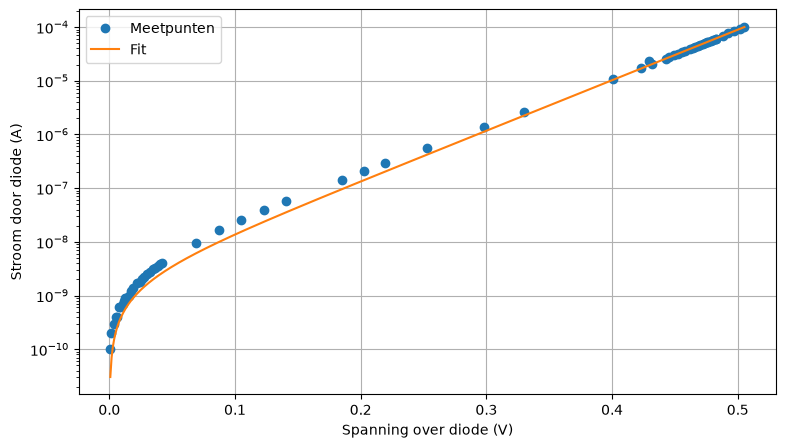

In [10]:
#Data processing and analysis:
def diode_model(U_D, I0, b):
    return I0 * np.expm1(b * U_D)

popt, pcov = curve_fit(
    diode_model,
    U_D_all,
    I_D_all,
    p0=[1e-9, 20]
)

I0, b = popt
u_I0, u_b = np.sqrt(np.diag(pcov))

U_fit = np.linspace(min(U_D_all), max(U_D_all), 500)

plt.figure(figsize=(9, 5))
plt.semilogy(U_D_all, I_D_all, 'o', label='Meetpunten')
plt.semilogy(U_fit, diode_model(U_fit, *popt), label='Fit')

plt.xlabel('Spanning over diode (V)')
plt.ylabel('Stroom door diode (A)')
plt.legend()
plt.grid()
plt.show()

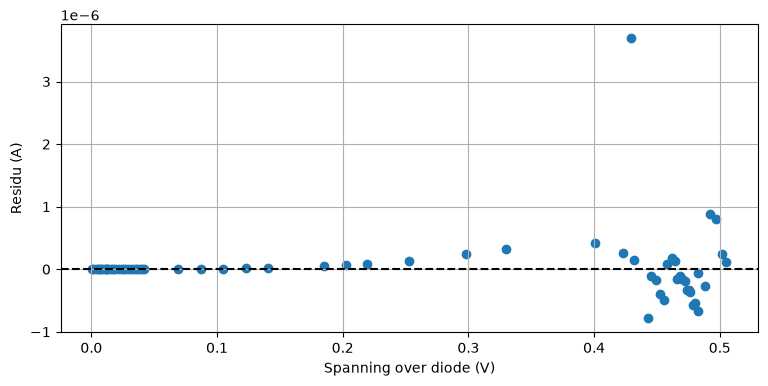

In [11]:
#Data processing and analysis:
residuen = I_D_all - diode_model(U_D_all, *popt)

plt.figure(figsize=(9, 4))
plt.scatter(U_D_all, residuen)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Spanning over diode (V)')
plt.ylabel('Residu (A)')
plt.grid()
plt.show()

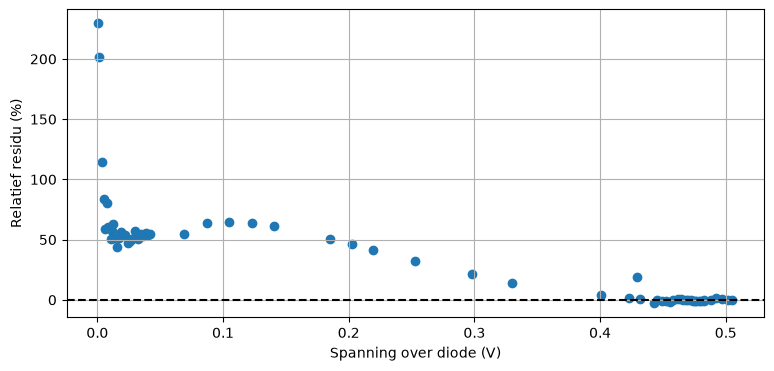

In [12]:
I_fit = diode_model(U_D_all, *popt)

res_rel = (I_D_all - I_fit) / I_fit * 100

plt.figure(figsize=(9, 4))
plt.scatter(U_D_all, res_rel)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Spanning over diode (V)')
plt.ylabel('Relatief residu (%)')
plt.grid()
plt.show()

In [16]:
# gewogen fit uitvoeren 
# Covariantie tussen U_D en I_D
cov_UI = (
    -(1 + 1/(R1*A)) / R1 * u_U_R**2
    - U_R_all**2 / (R1**4*A) * u_R1**2
)

# Iteratieve gewogen fit
popt_w = popt.copy()

for i in range(10):
    I0_w, b_w = popt_w

    dI_dU = I0_w * b_w * np.exp(b_w * U_D_all)

    sigma = np.sqrt(
        u_I_D**2 +
        (dI_dU * u_U_D)**2 -
        2 * dI_dU * cov_UI
    )

    popt_w, pcov_w = curve_fit(
        diode_model,
        U_D_all,
        I_D_all,
        p0=popt_w,
        sigma=sigma,
        absolute_sigma=True
    )

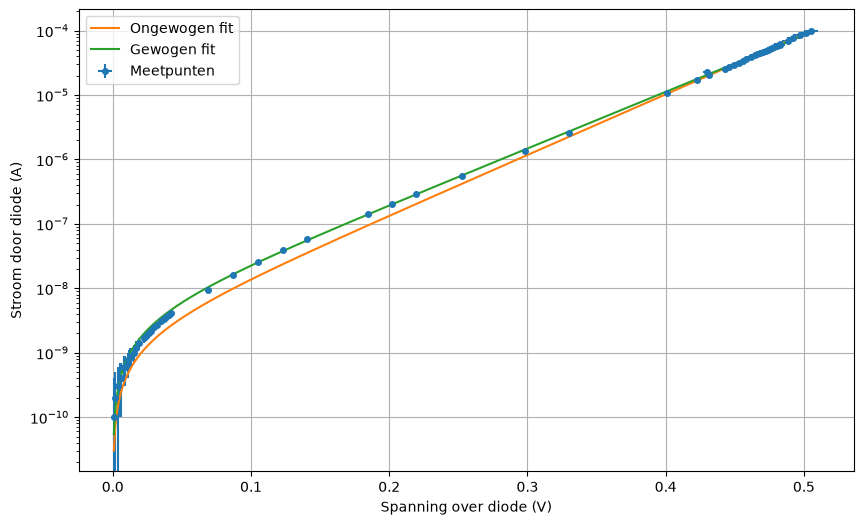

In [17]:
plt.figure(figsize=(10, 6))

plt.errorbar(
    U_D_all, I_D_all,
    xerr=u_U_D, yerr=u_I_D,
    fmt='o', label='Meetpunten',
    markersize=4
)

plt.plot(U_fit, diode_model(U_fit, *popt),
         label='Ongewogen fit')

plt.plot(U_fit, diode_model(U_fit, *popt_w),
         label='Gewogen fit')

plt.yscale('log')
plt.xlabel('Spanning over diode (V)')
plt.ylabel('Stroom door diode (A)')
plt.legend()
plt.grid()
plt.show()

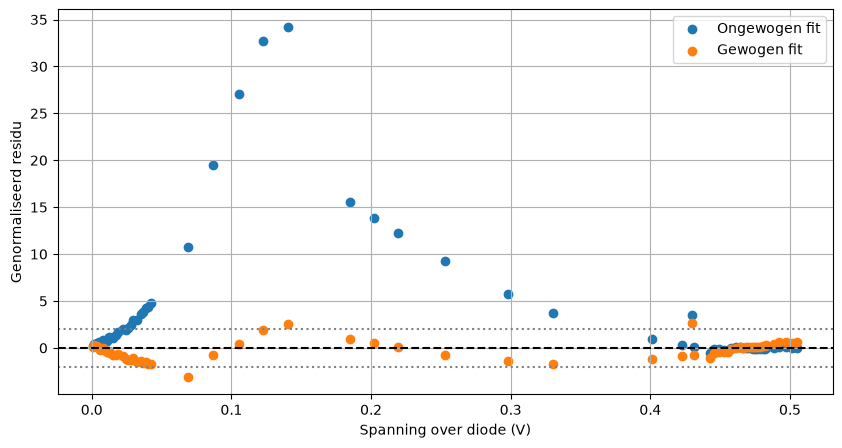

Ongewogen fit: 69.98617600869834
Gewogen fit: 1.0428727495560253


In [19]:
res_norm_w = (I_D_all - diode_model(U_D_all, *popt_w)) / sigma
res_norm = (I_D_all - diode_model(U_D_all, *popt)) / sigma

plt.figure(figsize=(10, 5))

plt.scatter(U_D_all, res_norm, label='Ongewogen fit')
plt.scatter(U_D_all, res_norm_w, label='Gewogen fit')

plt.axhline(0, color='black', linestyle='--')
plt.axhline(2, color='grey', linestyle=':')
plt.axhline(-2, color='grey', linestyle=':')

plt.xlabel('Spanning over diode (V)')
plt.ylabel('Genormaliseerd residu')
plt.legend()
plt.grid()
plt.show()

N = len(I_D_all)
p = 2

chi2_red = np.sum(res_norm**2) / (N-p)
chi2_red_w = np.sum(res_norm_w**2) / (N-p)

print('Ongewogen fit:', chi2_red)
print('Gewogen fit:', chi2_red_w)



**Describing the pattern in the processed data:**  


In [20]:
q = -1.602176634e-19
n = 2.0 # idealiteitsfactor n
u_n = 0.1 # onzekerheid van die factor

T = 293.15
u_T =1.

I0_w, b_w = popt_w
u_I0_w, u_b_w = np.sqrt(np.diag(pcov_w))

k_B_w = -q / (b_w * n * T)

u_k_B_w = k_B_w * np.sqrt(
    (u_b_w / b_w)**2 +
    (u_n / n)**2 +
    (u_T / T)**2
)

print(f'I0 = {I0_w:.3e} ± {u_I0_w:.2e} A')
print(f'b = {b_w:.3f} ± {u_b_w:.3f} 1/V')
print(f'k_B = {k_B_w:.4e} ± {u_k_B_w:.2e} J/K')

I0 = 3.424e-09 ± 3.32e-11 A
b = 20.241 ± 0.040 1/V
k_B = 1.3500e-23 ± 6.77e-25 J/K


In [21]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
k_B_ref = 1.380649e-23

s = abs(k_B_w - k_B_ref) / u_k_B_w

print(f's = {s:.3f}')

s = 0.452


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc